# Simulating water and ethanol

jostle simulates liquid water, ethanol and their mixtures with classical
molecular dynamics, in a periodic cubic box. The aim is to see how the liquids
are structured, through radial distribution functions (RDFs), how their
molecules vibrate, through bond phase-space diagrams, and how mixing the two
changes this.

This notebook simulates a water–ethanol mixture, then shows what happened: the
trajectory in VMD, the energies, the temperature, the RDFs and the phase-space
diagrams. Units throughout: nm, ps, amu, kJ/mol and K.

**Setup.** Install the package once, from the repository root, with
`pip install -e .[notebook]`, then start Jupyter (`jupyter lab`). The
[docs/internals.md](../docs/internals.md) documents every setting, the force field and the
modelling approximations to keep in mind when interpreting the results.

In [1]:
from pprint import pprint

from jostle import Config, Results, check_config, find_vmd, run

## 1. Choose the settings

All settings live in a `Config`, in three groups: `system` (what is simulated),
`numerics` (how it is approximated) and `recording` (what is measured), plus
`end_time`, `seed` and `output_dir`. Any setting can be given by name, whatever
its group. [docs/internals.md](../docs/internals.md#2-configuration) lists them all with their
defaults.

The cell below runs a small box: 2 nm of water and ethanol for 5 ps, which
takes a few minutes. Delete `box_length` and `end_time` to run the defaults
instead (a 4 nm box for 10 ps, which takes about 40 minutes), or uncomment
and change other settings. The default `dt` (0.25 fs) resolves the fast O–H
and C–H vibrations; at 1 fs the energy is noticeably less well conserved.
Each measurement has its own interval: energies every `energy_interval` (20),
trajectory frames every `trajectory_interval` (100) and RDFs every `rdf_interval`
(100). The phase space is recorded every step, but only over the last
`phase_space_window` (1 ps) of the run.

`run` checks the settings before it starts (so does `config.replace`, which
returns a changed copy). It then prints the expected size of the output files,
and warns about settings that would waste the run or a measurement (a `dt`
too large for the bond vibrations, an RDF recorded too often, a likely typo in
a bond or pair name, ...); `check_config(config)` shows the same without running.
Results are written to `output_dir`, in a folder named after the settings.

In [2]:
config = Config(
    box_length=2.0,                        # box edge (nm)
    end_time=5.0,                          # simulated time (ps)
    seed=1,                                # None: a different box each run
    rdf_bin_width=0.01,                    # RDF bin width (nm)
    # weights={"Water": 3, "Ethanol": 1},  # relative amounts of molecules
    # thermostat=False,                    # NVE instead of a thermostat
    # integrator="beeman",                 # or euler, verlet, velocity_verlet
    # trajectory_interval=100,             # steps between trajectory frames
    # phase_space_window=1.0,              # ps of phase space, at the end
    # rdf_pairs=["O~O (Water~Water)"],     # RDF pairs to record
    output_dir="../trajectories",
).validate()
pprint(config.to_dict(), sort_dicts=False)

{'system': {'weights': {'Water': 1.0, 'Ethanol': 1.0},
            'box_length': 2.0,
            'temperature': 298.15,
            'thermostat': True,
            'molecule_dir': 'C:\\Users\\olivi\\jostle\\src\\jostle\\data\\molecules'},
 'numerics': {'integrator': 'velocity_verlet', 'dt': 0.00025, 'lj_cutoff': 2.5},
 'recording': {'energy_interval': 20,
               'trajectory_interval': 100,
               'rdf_interval': 100,
               'record_potential_energies': True,
               'phase_space_bonds': ['O-H (Water)',
                                     'O-H (Ethanol)',
                                     'C-O (Ethanol)',
                                     'C-H (Ethanol)'],
               'phase_space_window': 1.0,
               'rdf_pairs': ['O~H (Water~Ethanol)',
                             'O~H (Ethanol~Ethanol)',
                             'O~H (Water~Water)',
                             'O~O (Water~Water)',
                             'O~O (Water~Ethanol)

## 2. Run the simulation

`run` builds the box, minimises its energy, integrates, and writes the
trajectory and the recorded data to the run folder. It returns a `Results`
object with all the recorded data. It makes no figures: those are made
below, when you ask for them.

To come back to a finished run later (after restarting the notebook, say),
load it instead of running again; everything below works on it:

```python
results = Results.load("../trajectories/<system>/<run>")
```

In [3]:
results = run(config)

Expected output: trajectory.xyz 11 MB (201 frames, 1044 atoms), results.npz up to 6.1 MB.
Creating initial configuration...
  Initialized 174 molecules (1044 atoms),
  on a grid of 6x6x6 positions. Effective weights:
    Water: 0.500
    Ethanol: 0.500


  Minimised the energy in 204 iterations (2.0 s): largest force below 1116 kJ/mol/nm, the thermal force of the stiffest bond.
Integrating...


  0%|          | 0/20000 [00:00<?, ?it/s]

  0%|          | 18/20000 [00:00<01:54, 174.32it/s]

  0%|          | 36/20000 [00:00<01:56, 172.01it/s]

...

100%|█████████▉| 19974/20000 [02:07<00:00, 153.81it/s]

100%|█████████▉| 19992/20000 [02:07<00:00, 158.82it/s]

100%|██████████| 20000/20000 [02:07<00:00, 156.63it/s]

  Integration took 127.7738 seconds (492 neighbour list builds)


Results written to ..\trajectories\1Water_1Ethanol_2nm_5ps_da2028e1


## 3. Watch the trajectory in VMD

The trajectory is `results.trajectory`: an `.xyz` file in Å, readable by
[VMD](https://www.ks.uiuc.edu/Research/vmd/) and similar tools. VMD is
optional. `view_in_vmd()` opens it in its own window, so the notebook stays
usable: the box outlined in red, surrounded by its 26 periodic images
(`show_periodic_images=False` leaves them out, which is lighter for large boxes). The
[docs/internals.md](../docs/internals.md#5-viewing-in-vmd) explains where jostle looks for VMD and
how to point it there (`vmd_path=...` or the `JOSTLE_VMD` environment variable).

The script VMD runs is kept in the run folder (`results.vmd_script`), so a
finished run can be reopened without Python: `vmd -e view_in_vmd.tcl` in that
folder.

In [4]:
if find_vmd() is not None:
    results.view_in_vmd(show_box=False, show_image_outlines=False)
else:
    print("VMD not found; see docs/internals.md for how to point jostle to it.")

Opened trajectory.xyz in VMD (C:\Program Files\University of Illinois\VMD2\vmd.exe)


## 4. Plot the measurements

Each `plot_*` method returns a matplotlib figure, which is shown below the
cell. Nothing is saved unless you ask: `save=True` saves the figure in the run
folder (under a standard name), and `save="path/name.pdf"` saves it anywhere,
in any format matplotlib knows.

The energy plot shows each potential energy term, the kinetic energy and their
total. LJ is cut off and shifted to make the forces go smoothly to zero at the
cutoff, which takes some attraction away; the plot shows the energy of this
simulated (shifted) potential. An estimate of the energy of the full LJ
potential, including the part beyond the cutoff, is kept in
`results.potential_energies["LJ"] + results.lj_correction`.

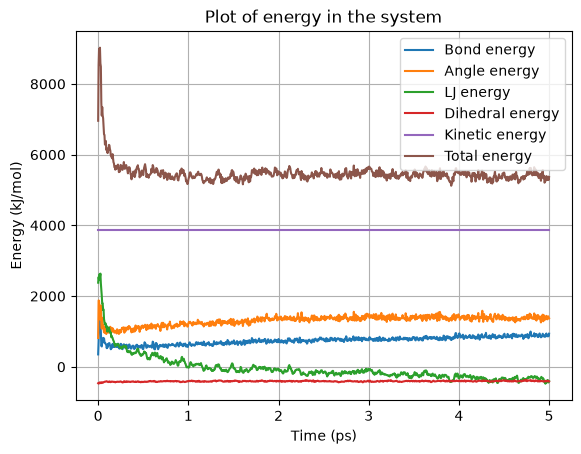

In [5]:
results.plot_energy()

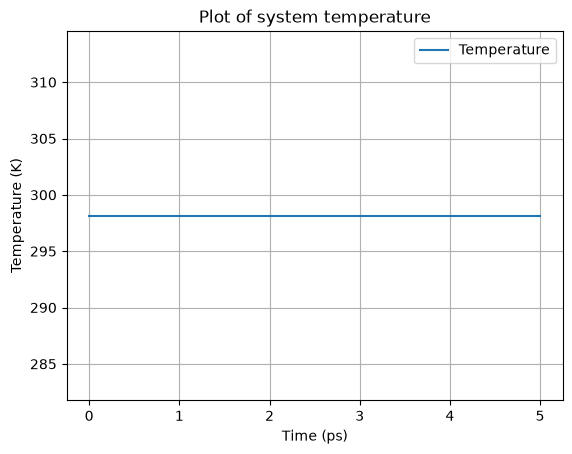

In [6]:
results.plot_temperature()

### Radial distribution functions

An animation of the running mean of g(r) of each recorded pair over time. One
pair can be shown with its 90% confidence interval instead (e.g.
`results.animate_rdf("O~O (Water~Water)")`); the interval comes from blocks of
`block_time` (default 1 ps), so it appears once two blocks are complete. It
takes a few seconds to make.

Each curve is one pair, such as the O atoms of water around the O atoms of
ethanol (`O~O (Water~Ethanol)`): its peaks show at which distances these atoms
are more likely to be found than in a uniform mixture, and g(r) tends to 1 at
large r. Comparing the water–water, ethanol–ethanol and water–ethanol pairs
shows how the two liquids arrange around each other.

  0%|          | 0/50 [00:00<?, ?it/s]

  4%|▍         | 2/50 [00:00<00:03, 14.65it/s]

  8%|▊         | 4/50 [00:00<00:05,  8.80it/s]

 12%|█▏        | 6/50 [00:00<00:05,  7.41it/s]

 14%|█▍        | 7/50 [00:00<00:05,  7.33it/s]

...

 94%|█████████▍| 47/50 [00:05<00:00,  7.87it/s]

 96%|█████████▌| 48/50 [00:06<00:00,  7.88it/s]

 98%|█████████▊| 49/50 [00:06<00:00,  7.91it/s]

100%|██████████| 50/50 [00:06<00:00,  7.97it/s]

100%|██████████| 50/50 [00:11<00:00,  4.53it/s]

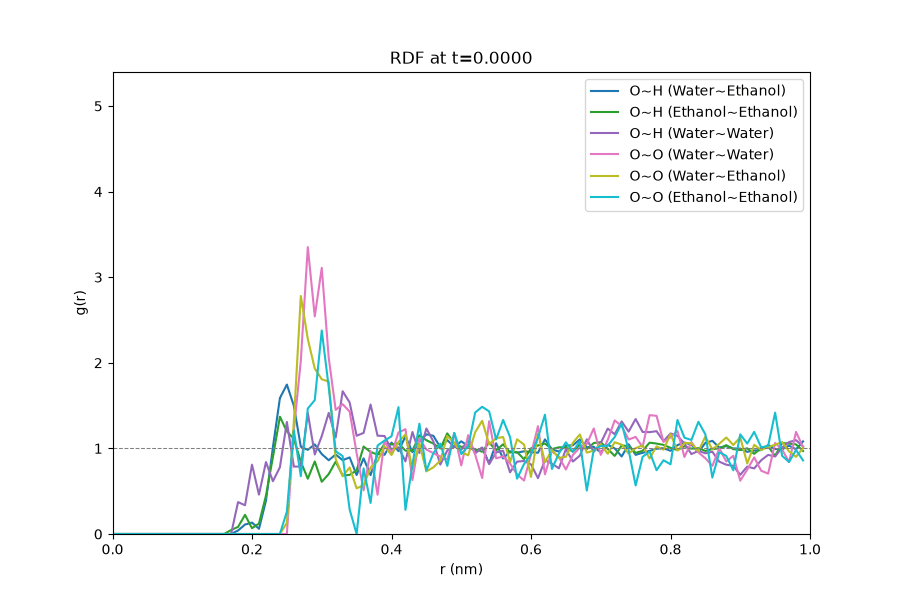

In [7]:
results.animate_rdf(max_frames=50)

### Phase space

Bond length against its rate of change, for a bond type named as in
`phase_space_bonds` (bond types absent from the box are skipped; without a
name, you get a figure for each tracked type). It shows the last
`phase_space_window` of the run, recorded every step, for up to 100 bonds of
each type spread through the box. This one is also saved, in the run folder's
`phase_space/`:

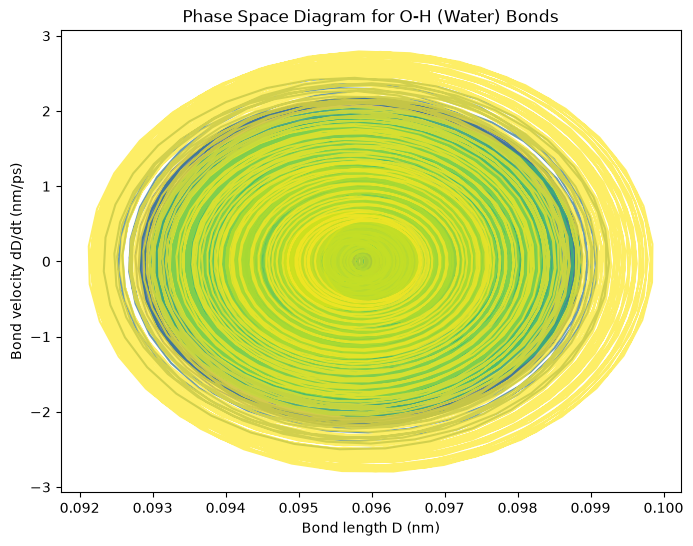

In [8]:
results.plot_phase_space("O-H (Water)", save=True)

Where the computation time went:

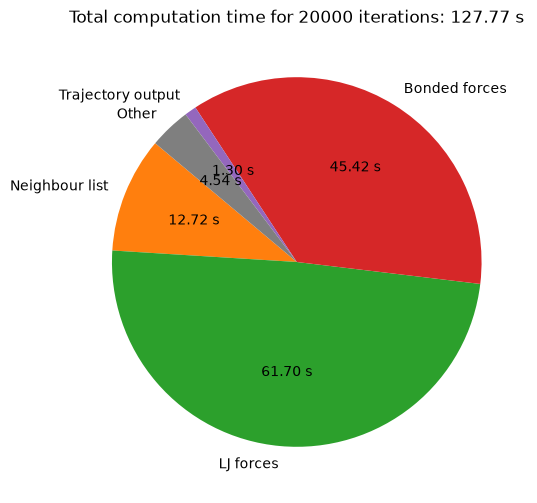

In [9]:
results.plot_timings()